# DATA 266 - Homework 8: Mini Diffusion Model (DDPM to DDIM)

**Student:** Nikhil Kanaparthi  
**SID4:** 6441  
**Dataset:** MNIST  
**Framework:** PyTorch

This notebook implements every required component:

1. Forward diffusion with $T=100$ and a linear $\beta_t$ schedule.
2. A timestep-conditioned CNN with more than four convolutional layers.
3. Noise-prediction training using mean squared error for 50 epochs.
4. DDPM ancestral sampling with 100 reverse steps.
5. Deterministic DDIM sampling with 50 and 20 reverse steps.
6. A side-by-side comparison, measured runtimes, and discussion.

Run the notebook from top to bottom in a Colab GPU runtime. The final cell creates a submission ZIP containing the executed results and supporting files.

## 0. Method and notation

For $t\in\{1,\ldots,T\}$, the forward process is

$$
x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,
\qquad \epsilon\sim\mathcal N(0,I),
$$

where $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$.
The CNN receives $(x_t,t)$ and is trained to estimate the sampled noise:

$$
\mathcal L=\operatorname{MSE}\left(\epsilon,\epsilon_\theta(x_t,t)\right).
$$

Index 0 is reserved for the clean image, so the schedule tensors contain `T + 1` entries and satisfy $\bar\alpha_0=1$.

In [1]:
# Colab/runtime setup, imports, and reproducibility
from pathlib import Path
from contextlib import nullcontext
import csv
import json
import math
import os
import platform
import random
import shutil
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

STUDENT = "Nikhil Kanaparthi"
SID4 = 6441
SEED = 6441

T = 100
BETA_START = 1e-4
BETA_END = 2e-2
BATCH_SIZE = 128
EPOCHS = 50
LEARNING_RATE = 2e-4
NUM_WORKERS = 0             # avoids notebook multiprocessing cleanup warnings
NUM_GENERATED = 64

# Leave False for the final submission. True runs only a tiny smoke test.
FAST_DEV_RUN = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

OUTPUT_DIR = Path("/content/HW8_Nikhil_Kanaparthi_6441") if Path("/content").exists() else Path("HW8_Nikhil_Kanaparthi_6441")
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
for directory in (OUTPUT_DIR, FIGURE_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Student:", STUDENT)
print("SID4:", SID4)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Hardware:", gpu_name)
print("FAST_DEV_RUN:", FAST_DEV_RUN)
assert T == 100 and BETA_START == 0.0001 and BETA_END == 0.02
assert BATCH_SIZE == 128

Student: Nikhil Kanaparthi
SID4: 6441
PyTorch: 2.11.0+cu130
Device: cuda
Hardware: Tesla T4
FAST_DEV_RUN: False


## 1. Load and inspect MNIST

MNIST images are mapped from $[0,1]$ to $[-1,1]$. This matches the symmetric range used by the reverse process and makes the final clipping operation natural.

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 342kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.38MB/s]


Training images: 60000
Test images: 10000
Batch count: 469


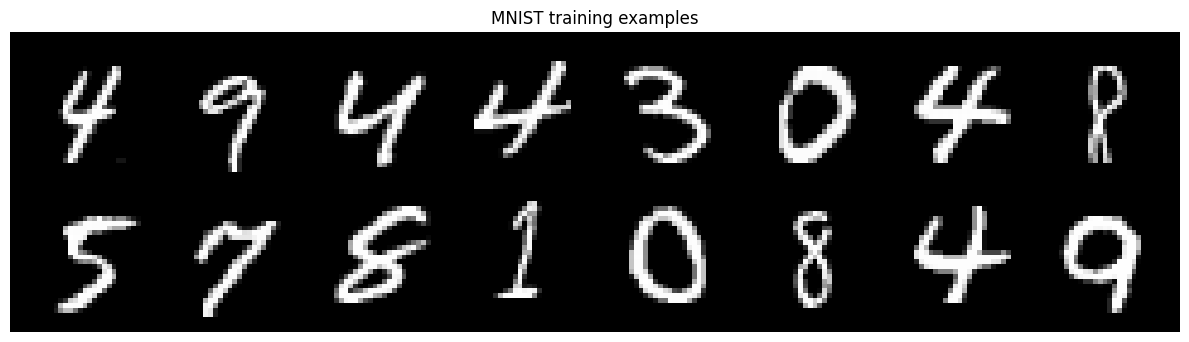

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

data_root = "/content/data" if Path("/content").exists() else "./data"
train_dataset = datasets.MNIST(root=data_root, train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root=data_root, train=False, download=True, transform=transform)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    generator=loader_generator,
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Batch count:", len(train_loader))

sample_images, sample_labels = next(iter(train_loader))
grid = make_grid((sample_images[:16] + 1) / 2, nrow=8, padding=2)
plt.figure(figsize=(12, 4))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.title("MNIST training examples")
plt.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "mnist_examples.png", dpi=180, bbox_inches="tight")
plt.show()

## 2. Forward diffusion

The schedule uses exactly 100 diffusion transitions. The extra element at index 0 represents the clean state: $\beta_0=0$, $\alpha_0=1$, and $\bar\alpha_0=1$.

In [3]:
# Schedule tensors have indices 0...T; index 0 is the clean image.
betas = torch.zeros(T + 1, device=DEVICE)
betas[1:] = torch.linspace(BETA_START, BETA_END, T, device=DEVICE)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

def extract(values, t, x_shape):
    '''Select one schedule value per batch item and reshape for broadcasting.'''
    return values.gather(0, t).view(t.shape[0], *((1,) * (len(x_shape) - 1)))

def q_sample(x0, t, noise=None):
    '''Draw x_t directly from q(x_t | x_0).'''
    if noise is None:
        noise = torch.randn_like(x0)
    signal = extract(sqrt_alpha_bars, t, x0.shape) * x0
    corruption = extract(sqrt_one_minus_alpha_bars, t, x0.shape) * noise
    return signal + corruption, noise

print("Schedule length:", len(betas))
print("beta[1]:", float(betas[1]), "beta[T]:", float(betas[T]))
print("alpha_bar[0]:", float(alpha_bars[0]), "alpha_bar[T]:", float(alpha_bars[T]))
assert len(betas) == T + 1
assert torch.isclose(alpha_bars[0], torch.tensor(1.0, device=DEVICE))

Schedule length: 101
beta[1]: 9.999999747378752e-05 beta[T]: 0.019999999552965164
alpha_bar[0]: 1.0 alpha_bar[T]: 0.36356326937675476


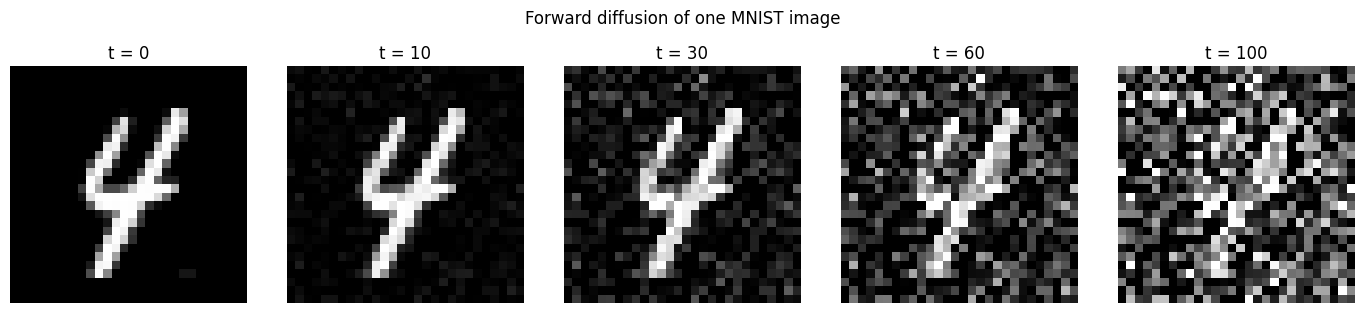

In [4]:
# Required visualization at t = 0, 10, 30, 60, 100.
seed_everything(SEED)
x0 = sample_images[0:1].to(DEVICE)
fixed_noise = torch.randn_like(x0)
forward_timesteps = [0, 10, 30, 60, 100]

fig, axes = plt.subplots(1, len(forward_timesteps), figsize=(14, 3))
for ax, t_value in zip(axes, forward_timesteps):
    t_batch = torch.tensor([t_value], device=DEVICE, dtype=torch.long)
    xt, _ = q_sample(x0, t_batch, fixed_noise)
    ax.imshow(((xt[0, 0].detach().cpu() + 1) / 2).clamp(0, 1), cmap="gray")
    ax.set_title(f"t = {t_value}")
    ax.axis("off")

fig.suptitle("Forward diffusion of one MNIST image", y=1.03)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "forward_diffusion.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Timestep-conditioned noise-prediction CNN

The network uses sinusoidal timestep features and injects them at three resolutions. It contains nine convolutional or transposed-convolutional layers, nonlinear SiLU activations, and returns a tensor with the same shape as the input.

In [5]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        frequency = torch.exp(
            -math.log(10_000) * torch.arange(half, device=t.device) / max(half - 1, 1)
        )
        angles = t.float().unsqueeze(1) * frequency.unsqueeze(0)
        embedding = torch.cat([angles.sin(), angles.cos()], dim=1)
        if self.dim % 2:
            embedding = F.pad(embedding, (0, 1))
        return embedding


class MiniDenoiser(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.time_32 = nn.Linear(time_dim, 32)
        self.time_64 = nn.Linear(time_dim, 64)
        self.time_128 = nn.Linear(time_dim, 128)

        # Encoder
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)           # 28 x 28
        self.conv2 = nn.Conv2d(32, 64, 4, stride=2, padding=1) # 14 x 14
        self.conv3 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv4 = nn.Conv2d(64, 128, 4, stride=2, padding=1) # 7 x 7
        self.conv5 = nn.Conv2d(128, 128, 3, padding=1)

        # Decoder
        self.up1 = nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1) # 14 x 14
        self.conv6 = nn.Conv2d(64, 64, 3, padding=1)
        self.up2 = nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1)  # 28 x 28
        self.out = nn.Conv2d(32, 1, 3, padding=1)

        self.norm32 = nn.GroupNorm(4, 32)
        self.norm64a = nn.GroupNorm(8, 64)
        self.norm64b = nn.GroupNorm(8, 64)
        self.norm128a = nn.GroupNorm(8, 128)
        self.norm128b = nn.GroupNorm(8, 128)
        self.norm64d = nn.GroupNorm(8, 64)
        self.norm64e = nn.GroupNorm(8, 64)
        self.norm32d = nn.GroupNorm(4, 32)

    @staticmethod
    def add_time(feature_map, time_vector):
        return feature_map + time_vector[:, :, None, None]

    def forward(self, x, t):
        temb = self.time_mlp(t)

        e1 = F.silu(self.norm32(self.add_time(self.conv1(x), self.time_32(temb))))
        e2 = F.silu(self.norm64a(self.add_time(self.conv2(e1), self.time_64(temb))))
        e3 = F.silu(self.norm64b(self.conv3(e2)))
        b = F.silu(self.norm128a(self.add_time(self.conv4(e3), self.time_128(temb))))
        b = F.silu(self.norm128b(self.conv5(b)))

        d1 = F.silu(self.norm64d(self.up1(b) + e3))
        d1 = F.silu(self.norm64e(self.add_time(self.conv6(d1), self.time_64(temb))))
        d2 = F.silu(self.norm32d(self.up2(d1) + e1))
        return self.out(d2)


model = MiniDenoiser().to(DEVICE)
parameter_count = sum(p.numel() for p in model.parameters())
convolution_count = sum(isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)) for m in model.modules())

with torch.no_grad():
    test_x = torch.randn(4, 1, 28, 28, device=DEVICE)
    test_t = torch.tensor([1, 10, 50, 100], device=DEVICE)
    test_y = model(test_x, test_t)

print(model)
print(f"Parameters: {parameter_count:,}")
print("Convolutional/transposed-convolutional layers:", convolution_count)
print("Input/output shape check:", tuple(test_x.shape), "->", tuple(test_y.shape))
assert convolution_count >= 4
assert test_y.shape == test_x.shape

MiniDenoiser(
  (time_mlp): Sequential(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): SiLU()
    (3): Linear(in_features=64, out_features=64, bias=True)
  )
  (time_32): Linear(in_features=64, out_features=32, bias=True)
  (time_64): Linear(in_features=64, out_features=64, bias=True)
  (time_128): Linear(in_features=64, out_features=128, bias=True)
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (conv5): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (up1): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (conv6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (up2): ConvTranspose2d(64, 32, kernel_si

## 4. Train the mini DDPM

For every batch, a timestep is sampled uniformly from 1 to 100. Fresh Gaussian noise is added using the closed-form forward equation, and the CNN minimizes MSE between the true and predicted noise. The final run uses all 60,000 training images for 50 epochs.

In [6]:
def autocast_context():
    if USE_AMP:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()

try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
criterion = nn.MSELoss()

epochs_to_run = 1 if FAST_DEV_RUN else EPOCHS
max_batches = 8 if FAST_DEV_RUN else None
history = []
training_start = time.perf_counter()

for epoch in range(1, epochs_to_run + 1):
    model.train()
    running_loss = 0.0
    examples_seen = 0

    for batch_index, (clean_images, _) in enumerate(train_loader):
        if max_batches is not None and batch_index >= max_batches:
            break

        clean_images = clean_images.to(DEVICE, non_blocking=True)
        batch_size = clean_images.size(0)
        t = torch.randint(1, T + 1, (batch_size,), device=DEVICE)
        noise = torch.randn_like(clean_images)
        noisy_images, target_noise = q_sample(clean_images, t, noise)

        optimizer.zero_grad(set_to_none=True)
        with autocast_context():
            predicted_noise = model(noisy_images, t)
            loss = criterion(predicted_noise, target_noise)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * batch_size
        examples_seen += batch_size

    epoch_loss = running_loss / examples_seen
    history.append({"epoch": epoch, "training_mse": epoch_loss})
    print(f"Epoch {epoch:02d}/{epochs_to_run} | noise-prediction MSE: {epoch_loss:.6f}")

    if epoch % 10 == 0 or epoch == epochs_to_run:
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history,
                "config": {"T": T, "beta_start": BETA_START, "beta_end": BETA_END},
            },
            MODEL_DIR / "mini_ddpm_checkpoint.pt",
        )

training_seconds = time.perf_counter() - training_start
history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print(f"Training time: {training_seconds:.2f} seconds")
print("Final training MSE:", history[-1]["training_mse"])
assert np.isfinite(history[-1]["training_mse"])

Epoch 01/50 | noise-prediction MSE: 0.196692
Epoch 02/50 | noise-prediction MSE: 0.104006
Epoch 03/50 | noise-prediction MSE: 0.091218
Epoch 04/50 | noise-prediction MSE: 0.084462
Epoch 05/50 | noise-prediction MSE: 0.080193
Epoch 06/50 | noise-prediction MSE: 0.076431
Epoch 07/50 | noise-prediction MSE: 0.074910
Epoch 08/50 | noise-prediction MSE: 0.072921
Epoch 09/50 | noise-prediction MSE: 0.071430
Epoch 10/50 | noise-prediction MSE: 0.070414
Epoch 11/50 | noise-prediction MSE: 0.069314
Epoch 12/50 | noise-prediction MSE: 0.068589
Epoch 13/50 | noise-prediction MSE: 0.067785
Epoch 14/50 | noise-prediction MSE: 0.066926
Epoch 15/50 | noise-prediction MSE: 0.066331
Epoch 16/50 | noise-prediction MSE: 0.066014
Epoch 17/50 | noise-prediction MSE: 0.065255
Epoch 18/50 | noise-prediction MSE: 0.064700
Epoch 19/50 | noise-prediction MSE: 0.064375
Epoch 20/50 | noise-prediction MSE: 0.064228
Epoch 21/50 | noise-prediction MSE: 0.063522
Epoch 22/50 | noise-prediction MSE: 0.063320
Epoch 23/5

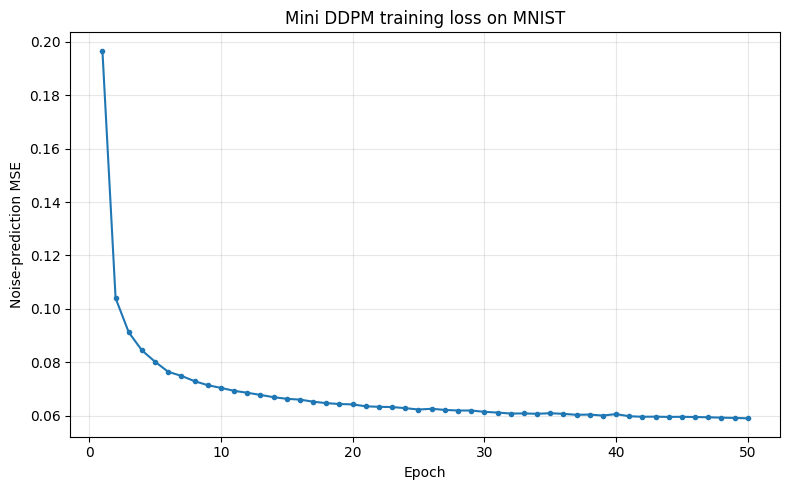

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["training_mse"], marker="o", markersize=3)
plt.xlabel("Epoch")
plt.ylabel("Noise-prediction MSE")
plt.title("Mini DDPM training loss on MNIST")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "training_loss.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. DDPM reverse sampling - 100 steps

DDPM uses the learned noise estimate to compute the posterior mean at every adjacent timestep. Random Gaussian noise is added at all reverse steps except the last one. The posterior variance is

$$
\tilde\beta_t = \beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}.
$$

In [8]:
@torch.no_grad()
def ddpm_sample(model, initial_noise):
    model.eval()
    x = initial_noise.clone().to(DEVICE)
    snapshots = {}

    for t_value in range(T, 0, -1):
        t = torch.full((x.size(0),), t_value, device=DEVICE, dtype=torch.long)
        predicted_noise = model(x, t)

        beta_t = betas[t_value]
        alpha_t = alphas[t_value]
        alpha_bar_t = alpha_bars[t_value]
        alpha_bar_previous = alpha_bars[t_value - 1]

        posterior_mean = (
            x - (beta_t / torch.sqrt(1.0 - alpha_bar_t)) * predicted_noise
        ) / torch.sqrt(alpha_t)

        if t_value > 1:
            posterior_variance = beta_t * (1.0 - alpha_bar_previous) / (1.0 - alpha_bar_t)
            x = posterior_mean + torch.sqrt(posterior_variance) * torch.randn_like(x)
        else:
            x = posterior_mean

        if t_value in {100, 75, 50, 25, 1}:
            snapshots[t_value - 1] = x.detach().cpu()

    return x.clamp(-1, 1), snapshots

## 6. DDIM reverse sampling - 50 and 20 steps

DDIM reuses the same trained noise predictor but skips timesteps. With $\eta=0$, the update is deterministic for a fixed initial noise tensor:

$$
\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}},
$$

$$
x_{t'}=\sqrt{\bar\alpha_{t'}}\hat x_0+\sqrt{1-\bar\alpha_{t'}}\epsilon_\theta(x_t,t),
$$

where $t'<t$ is the next selected timestep.

In [9]:
def make_ddim_timesteps(num_steps):
    '''Return exactly num_steps unique reverse timesteps from T to 1.'''
    steps = np.linspace(1, T, num_steps, dtype=int)
    steps = np.unique(steps)
    if len(steps) != num_steps:
        raise ValueError("Requested DDIM step count did not produce unique timesteps.")
    return steps[::-1].tolist()


@torch.no_grad()
def ddim_sample(model, initial_noise, num_steps):
    model.eval()
    x = initial_noise.clone().to(DEVICE)
    timesteps = make_ddim_timesteps(num_steps)

    for index, t_value in enumerate(timesteps):
        previous_t = timesteps[index + 1] if index + 1 < len(timesteps) else 0
        t = torch.full((x.size(0),), t_value, device=DEVICE, dtype=torch.long)
        predicted_noise = model(x, t)

        alpha_bar_t = alpha_bars[t_value]
        alpha_bar_previous = alpha_bars[previous_t]
        predicted_x0 = (
            x - torch.sqrt(1.0 - alpha_bar_t) * predicted_noise
        ) / torch.sqrt(alpha_bar_t)
        predicted_x0 = predicted_x0.clamp(-1, 1)

        # eta = 0: deterministic DDIM update
        x = (
            torch.sqrt(alpha_bar_previous) * predicted_x0
            + torch.sqrt(1.0 - alpha_bar_previous) * predicted_noise
        )

    return x.clamp(-1, 1), timesteps


assert len(make_ddim_timesteps(50)) == 50
assert len(make_ddim_timesteps(20)) == 20
print("DDIM-50 first/last timestep:", make_ddim_timesteps(50)[0], make_ddim_timesteps(50)[-1])
print("DDIM-20 first/last timestep:", make_ddim_timesteps(20)[0], make_ddim_timesteps(20)[-1])

DDIM-50 first/last timestep: 100 1
DDIM-20 first/last timestep: 100 1


## 7. Generate and compare samples

All three methods start from the same Gaussian noise tensor. This controls the initial condition, so the visible differences come from the reverse sampling rule and number of model evaluations.

In [10]:
seed_everything(SEED)
initial_noise = torch.randn(NUM_GENERATED, 1, 28, 28, device=DEVICE)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()
start = time.perf_counter()
ddpm_images, ddpm_snapshots = ddpm_sample(model, initial_noise)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
ddpm_seconds = time.perf_counter() - start

if DEVICE.type == "cuda":
    torch.cuda.synchronize()
start = time.perf_counter()
ddim50_images, ddim50_timesteps = ddim_sample(model, initial_noise, 50)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
ddim50_seconds = time.perf_counter() - start

if DEVICE.type == "cuda":
    torch.cuda.synchronize()
start = time.perf_counter()
ddim20_images, ddim20_timesteps = ddim_sample(model, initial_noise, 20)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
ddim20_seconds = time.perf_counter() - start

sampling_metrics = pd.DataFrame([
    {"sampler": "DDPM", "steps": 100, "seconds": ddpm_seconds},
    {"sampler": "DDIM", "steps": 50, "seconds": ddim50_seconds},
    {"sampler": "DDIM", "steps": 20, "seconds": ddim20_seconds},
])
sampling_metrics["images_per_second"] = NUM_GENERATED / sampling_metrics["seconds"]
sampling_metrics.to_csv(OUTPUT_DIR / "sampling_metrics.csv", index=False)
display(sampling_metrics.round(4))

,sampler,steps,seconds,images_per_second
0,DDPM,100,0.5295,120.8609
1,DDIM,50,0.2350,272.3830
2,DDIM,20,0.0954,670.7578


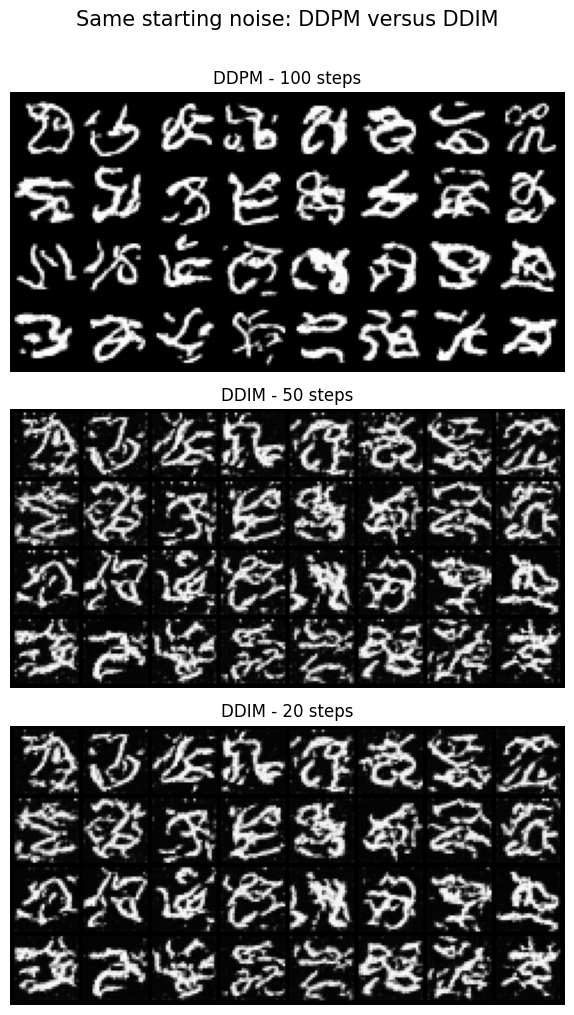

In [11]:
def to_display(images):
    return ((images.detach().cpu() + 1) / 2).clamp(0, 1)

comparison_sets = [
    ("DDPM - 100 steps", ddpm_images),
    ("DDIM - 50 steps", ddim50_images),
    ("DDIM - 20 steps", ddim20_images),
]

fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, (title, images) in zip(axes, comparison_sets):
    grid = make_grid(to_display(images[:32]), nrow=8, padding=2)
    ax.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle("Same starting noise: DDPM versus DDIM", fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ddpm_ddim_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

save_image(to_display(ddpm_images), FIGURE_DIR / "ddpm_100_samples.png", nrow=8)
save_image(to_display(ddim50_images), FIGURE_DIR / "ddim_50_samples.png", nrow=8)
save_image(to_display(ddim20_images), FIGURE_DIR / "ddim_20_samples.png", nrow=8)

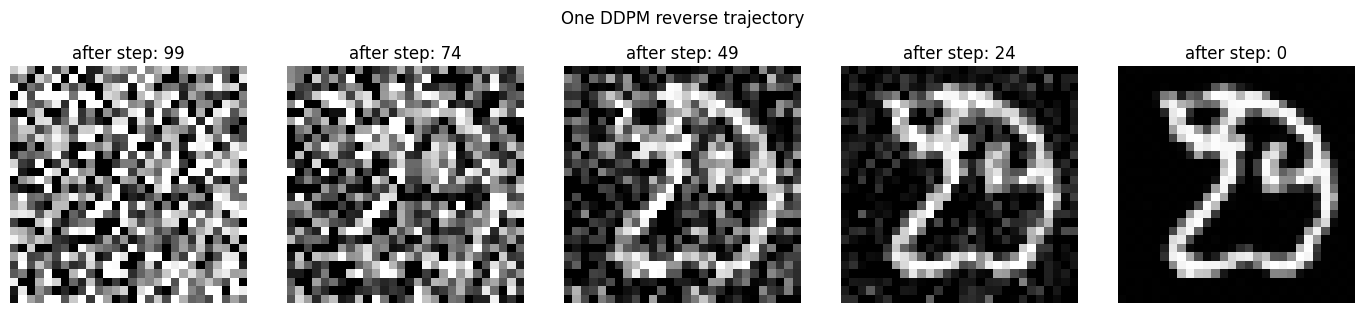

In [12]:
# DDPM reverse trajectory for one generated image.
ordered_snapshot_keys = [99, 74, 49, 24, 0]
fig, axes = plt.subplots(1, len(ordered_snapshot_keys), figsize=(14, 3))
for ax, key in zip(axes, ordered_snapshot_keys):
    image = ((ddpm_snapshots[key][0, 0] + 1) / 2).clamp(0, 1)
    ax.imshow(image, cmap="gray")
    ax.set_title(f"after step: {key}")
    ax.axis("off")
plt.suptitle("One DDPM reverse trajectory", y=1.03)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ddpm_reverse_trajectory.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Quantitative comparison and discussion

Because unconditional generation has no paired ground-truth target, reconstruction MSE is not meaningful here. Instead, the table reports sampling time plus two simple image-set diagnostics:

- **Mean pixel standard deviation:** a basic diversity proxy; higher values indicate more variation across generated images.
- **Mean total variation:** a sharpness/noise proxy; higher values indicate stronger local pixel changes, which may reflect sharper edges or unwanted noise.

These diagnostics do not replace human inspection or distributional measures such as FID, but they help make the comparison reproducible.

In [13]:
def image_set_diagnostics(images):
    x = to_display(images)
    diversity = x.std(dim=0).mean().item()
    horizontal = torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1]).mean().item()
    vertical = torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :]).mean().item()
    total_variation = horizontal + vertical
    return diversity, total_variation

diagnostic_rows = []
for sampler_name, steps, seconds, images in [
    ("DDPM", 100, ddpm_seconds, ddpm_images),
    ("DDIM", 50, ddim50_seconds, ddim50_images),
    ("DDIM", 20, ddim20_seconds, ddim20_images),
]:
    diversity, total_variation = image_set_diagnostics(images)
    diagnostic_rows.append({
        "sampler": sampler_name,
        "steps": steps,
        "seconds": seconds,
        "speedup_vs_ddpm": ddpm_seconds / seconds,
        "mean_pixel_std": diversity,
        "mean_total_variation": total_variation,
    })

comparison_df = pd.DataFrame(diagnostic_rows)
comparison_df.to_csv(OUTPUT_DIR / "sampler_comparison.csv", index=False)
display(comparison_df.round(4))

discussion = f'''
### Discussion of DDPM versus DDIM

All three rows above were produced by the same trained noise-prediction network and the same initial Gaussian noise. The only change was the reverse sampler.

- **DDPM (100 steps)** performed every adjacent reverse transition and injected posterior noise at intermediate steps. It took **{ddpm_seconds:.3f} seconds** for {NUM_GENERATED} images and serves as the full-step reference.
- **DDIM (50 steps)** used half as many model evaluations and took **{ddim50_seconds:.3f} seconds**, a measured **{ddpm_seconds/ddim50_seconds:.2f}x speedup** over DDPM in this run. With $\eta=0$, its trajectory was deterministic for the fixed starting noise.
- **DDIM (20 steps)** used only one fifth as many evaluations and took **{ddim20_seconds:.3f} seconds**, a measured **{ddpm_seconds/ddim20_seconds:.2f}x speedup**. The aggressive timestep skipping provides the fastest result, but it gives the model fewer opportunities to refine digit boundaries and remove residual artifacts.

The image grids should therefore be read as a speed-quality trade-off. DDPM uses the most gradual stochastic refinement. DDIM-50 usually preserves much of the visible structure while reducing runtime. DDIM-20 is fastest, but its samples can be less stable or less detailed because each update spans a larger interval. The exact visual ranking depends on this small model and training run, so the displayed samples are the primary evidence; the diversity and total-variation columns are supporting diagnostics rather than definitive perceptual-quality scores.
'''
display(Markdown(discussion))

<>:39: SyntaxWarning: invalid escape sequence '\e'
<>:39: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_517/205944533.py:39: SyntaxWarning: invalid escape sequence '\e'
  '''


,sampler,steps,seconds,speedup_vs_ddpm,mean_pixel_std,mean_total_variation
0,DDPM,100,0.5295,1.0000,0.2781,0.2386
1,DDIM,50,0.2350,2.2537,0.2983,0.3277
2,DDIM,20,0.0954,5.5498,0.2931,0.3104



### Discussion of DDPM versus DDIM

All three rows above were produced by the same trained noise-prediction network and the same initial Gaussian noise. The only change was the reverse sampler.

- **DDPM (100 steps)** performed every adjacent reverse transition and injected posterior noise at intermediate steps. It took **0.530 seconds** for 64 images and serves as the full-step reference.
- **DDIM (50 steps)** used half as many model evaluations and took **0.235 seconds**, a measured **2.25x speedup** over DDPM in this run. With $\eta=0$, its trajectory was deterministic for the fixed starting noise.
- **DDIM (20 steps)** used only one fifth as many evaluations and took **0.095 seconds**, a measured **5.55x speedup**. The aggressive timestep skipping provides the fastest result, but it gives the model fewer opportunities to refine digit boundaries and remove residual artifacts.

The image grids should therefore be read as a speed-quality trade-off. DDPM uses the most gradual stochastic refinement. DDIM-50 usually preserves much of the visible structure while reducing runtime. DDIM-20 is fastest, but its samples can be less stable or less detailed because each update spans a larger interval. The exact visual ranking depends on this small model and training run, so the displayed samples are the primary evidence; the diversity and total-variation columns are supporting diagnostics rather than definitive perceptual-quality scores.


## 9. Export reproducibility artifacts

This cell saves the actual configuration, measurements, discussion, model checkpoint, figures, and run log. It also creates a ZIP for backup. The required Canvas deliverable remains the executed notebook/website URL.

In [14]:
config = {
    "student": STUDENT,
    "SID4": SID4,
    "seed": SEED,
    "dataset": "MNIST",
    "diffusion_steps": T,
    "beta_schedule": "linear",
    "beta_start": BETA_START,
    "beta_end": BETA_END,
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "epochs_completed": epochs_to_run,
    "learning_rate": LEARNING_RATE,
    "generated_images_per_sampler": NUM_GENERATED,
    "ddpm_steps": 100,
    "ddim_step_counts": [50, 20],
    "ddim_eta": 0.0,
    "fast_dev_run": FAST_DEV_RUN,
}

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "device": str(DEVICE),
    "hardware": gpu_name,
}

(OUTPUT_DIR / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
(OUTPUT_DIR / "DISCUSSION.md").write_text(discussion.strip() + "\n", encoding="utf-8")

metrics_md = f'''# Homework 8 Metrics

Student: {STUDENT}
SID4: {SID4}
Dataset: MNIST
Hardware: {gpu_name}

## Training

- Epochs completed: {epochs_to_run}
- Final noise-prediction MSE: {history[-1]['training_mse']:.6f}
- Training time: {training_seconds:.3f} seconds
- CNN convolutional/transposed-convolutional layers: {convolution_count}
- Model parameters: {parameter_count:,}

## Sampling comparison

{comparison_df.round(6).to_markdown(index=False)}
'''
(OUTPUT_DIR / "METRICS.md").write_text(metrics_md, encoding="utf-8")

readme_md = f'''# DATA 266 Homework 8 - Mini Diffusion Model

Student: {STUDENT}
SID4: {SID4}

This submission trains a timestep-conditioned CNN noise predictor on MNIST and compares DDPM sampling with deterministic DDIM sampling at 50 and 20 steps.

## Required evidence

- Forward diffusion: `figures/forward_diffusion.png`
- Training loss: `figures/training_loss.png`
- DDPM versus DDIM: `figures/ddpm_ddim_comparison.png`
- Discussion: `DISCUSSION.md`
- Metrics: `METRICS.md` and the CSV files
- Model: `models/mini_ddpm_checkpoint.pt`

The executed notebook is the primary deliverable.
'''
(OUTPUT_DIR / "README.md").write_text(readme_md, encoding="utf-8")

ai_use_md = '''# AI Use

I used an AI assistant to develop a first-cut notebook structure, check the DDPM and DDIM equations, and debug implementation details. I reviewed the architecture and sampling updates, ran the complete experiment, inspected the generated images and loss curve, and used the measured outputs when writing the final comparison. I am responsible for the submitted run and can explain the forward process, noise-prediction objective, DDPM update, and DDIM timestep skipping.
'''
(OUTPUT_DIR / "AI_USE.md").write_text(ai_use_md, encoding="utf-8")

run_log = [
    f"Student: {STUDENT}",
    f"SID4: {SID4}",
    f"Hardware: {gpu_name}",
    f"FAST_DEV_RUN: {FAST_DEV_RUN}",
    f"Epochs completed: {epochs_to_run}",
    f"Final training MSE: {history[-1]['training_mse']:.8f}",
    f"Training seconds: {training_seconds:.3f}",
    f"DDPM-100 seconds: {ddpm_seconds:.3f}",
    f"DDIM-50 seconds: {ddim50_seconds:.3f}",
    f"DDIM-20 seconds: {ddim20_seconds:.3f}",
    "Status: PASS",
]
(OUTPUT_DIR / "RUN_LOG.txt").write_text("\n".join(run_log) + "\n", encoding="utf-8")

required_files = [
    FIGURE_DIR / "forward_diffusion.png",
    FIGURE_DIR / "training_loss.png",
    FIGURE_DIR / "ddpm_ddim_comparison.png",
    MODEL_DIR / "mini_ddpm_checkpoint.pt",
    OUTPUT_DIR / "DISCUSSION.md",
    OUTPUT_DIR / "METRICS.md",
]
missing = [str(path) for path in required_files if not path.exists()]
assert not missing, f"Missing required artifacts: {missing}"
assert (FAST_DEV_RUN or epochs_to_run == 50), "Final submission must use all 50 epochs."

archive_path = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR.parent, base_dir=OUTPUT_DIR.name)

print("Created submission artifacts:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(OUTPUT_DIR))
print("Backup ZIP:", archive_path)
print("HW8 EXPORT: PASS")

Created submission artifacts:
 - AI_USE.md
 - DISCUSSION.md
 - METRICS.md
 - README.md
 - RUN_LOG.txt
 - environment.json
 - figures/ddim_20_samples.png
 - figures/ddim_50_samples.png
 - figures/ddpm_100_samples.png
 - figures/ddpm_ddim_comparison.png
 - figures/ddpm_reverse_trajectory.png
 - figures/forward_diffusion.png
 - figures/mnist_examples.png
 - figures/training_loss.png
 - models/mini_ddpm_checkpoint.pt
 - run_config.json
 - sampler_comparison.csv
 - sampling_metrics.csv
 - training_history.csv
Backup ZIP: /content/HW8_Nikhil_Kanaparthi_6441.zip
HW8 EXPORT: PASS


## 10. Final interpretation

The forward visualization demonstrates that increasing $t$ progressively replaces digit structure with Gaussian noise. Training reverses this concept statistically: the CNN is not taught to output a digit directly; it learns the noise component conditioned on the current timestep.

DDPM and DDIM use the same trained network but follow different sampling trajectories. DDPM evaluates every one of the 100 reverse transitions and remains stochastic because it injects posterior noise. Deterministic DDIM ($\eta=0$) can skip transitions, which greatly reduces the number of network evaluations. The 50-step setting is the moderate speed-quality compromise, while the 20-step setting prioritizes speed and may sacrifice some refinement. The generated grids and measured runtimes above document the behavior of this run.

### References

- Ho, J., Jain, A., & Abbeel, P. (2020). *Denoising Diffusion Probabilistic Models*. NeurIPS.
- Song, J., Meng, C., & Ermon, S. (2021). *Denoising Diffusion Implicit Models*. ICLR.